# Phase 3 - Machine Learning

Oleh Kysil: 50%, Valeriia Petrishka: 50%.

The target is `failure` for the observed measurement cycle

## Data and evaluation protocol

Reproduce Phase 2's deterministic cleaning, joins and 80/20 unit split from the three source CSVs. Within the development set, use the same five traning groups for every model. All readings from a unit stay together, in one group. Fit imputation, transformations, encoding and any variance filtering inside each training group.

Use all 17 candidate attributes from Phase 2 for each model. Unit IDs are used only for splitting, and `failure` is extracted before preprocessing.

In [1]:
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, KBinsDiscretizer, OneHotEncoder, PowerTransformer, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 1234

In [2]:
# CSV files are in ../dataset relative to the src folder
src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
gateways_df = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
readings_df = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
units_df = pd.read_csv(dataset_dir / "units.csv")

In [3]:
column_names = {
    "idUnit": "id_unit",
    "idDepot": "id_depot",
    "gatewayId": "gateway_id",
    "Ipv4": "ipv4",
    "dbmSignal": "dbm_signal",
    "Technician": "technician",
    "motorCurrent": "motor_current",
    "dpFilter": "dp_filter",
    "oilTemperature": "oil_temperature",
    "pressureReservoir": "pressure_reservoir",
    "pressureOil": "pressure_oil",
    "humidityIntake": "humidity_intake",
    "classDuty": "class_duty",
    "Manufacturer": "manufacturer",
    "hoursService": "hours_service",
}

tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
date_columns = {"gateways": "date_install", "readings": "ts_cycle", "units": "last_overhaul"}
normalized = {}

for name, table in tables.items():

    # remove exact duplicate rows so repeated copies do not bias the analysis
    frame = table.drop_duplicates().copy()
    # rename columns to snake_case in the cleaned tables
    frame = frame.rename(columns=column_names)
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)

    for column in [c for c in ["id_unit", "id_depot"] if c in frame]:
        key_text = frame[column].astype("string")

        if name == "readings" and column == "id_unit": 
            # remove the U prefix to match the integer IDs in the metadata tables
            key_text = key_text.str.replace(r"^U", "", regex=True)

        numeric = pd.to_numeric(key_text, errors="coerce")
        valid = numeric.notna() & np.isfinite(numeric) & numeric.ge(0) & numeric.mod(1).eq(0)

        # replace invalid IDs with missing value, zero is a valid depot ID
        frame[column] = numeric.where(valid).astype("Int64")

    frame[date_columns[name]] = pd.to_datetime(frame[date_columns[name]], format="mixed", errors="coerce")

    if name == "units":
        frame["class_duty"] = frame["class_duty"].str.lower().replace({"h": "heavy", "l": "light", "n": "normal"})

    # remove full-row duplicates that become identical after format normalization
    normalized[name] = frame.drop_duplicates().copy()

gateways_clean = normalized["gateways"]
readings_clean = normalized["readings"]
units_clean = normalized["units"]

In [4]:
sensor_columns = ["motor_current", "dp_filter", "oil_temperature", "pressure_reservoir", "pressure_oil", "rms_vibration", "flowmeter", "humidity_intake", "current_aux"]

for column in sensor_columns:
    values = readings_clean[column]
    invalid = values.notna() & ~np.isfinite(values)

    if column == "oil_temperature":
        invalid |= values.eq(-999)

    if column == "humidity_intake":
        invalid |= values.notna() & ~values.between(0, 100)

    readings_clean.loc[invalid, column] = np.nan

invalid_hours = units_clean["hours_service"].lt(0) | (units_clean["hours_service"].notna() & ~np.isfinite(units_clean["hours_service"]))

# remove negative or infinite service hours by replacing them with missing values
units_clean.loc[invalid_hours, "hours_service"] = np.nan
invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)

# remove coordinates outside the valid longitude range
gateways_clean.loc[invalid_longitude, "lon"] = np.nan

In [5]:
cycle_keys = ["id_unit", "ts_cycle"]
conflicting_labels = readings_clean.groupby(cycle_keys, dropna=False)["failure"].transform("nunique").gt(1)
valid_readings = readings_clean["id_unit"].notna() & readings_clean["ts_cycle"].notna()
valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels

# remove readings with invalid IDs/dates/labels or unresolved contradictory cycle labels
readings_for_merge = readings_clean.loc[valid_readings].copy()

# exclude unassigned gateways from the unit join
linked_gateways = gateways_clean.loc[gateways_clean["id_unit"].notna()].copy()
gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}" for c in linked_gateways if c != "id_unit"})
integrated_df = readings_for_merge.merge(units_clean, on="id_unit", how="left", validate="many_to_one", indicator="unit_match")

# remove readings whose IDs have no matching unit metadata
cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()

# remove the temporary merge indicator once unmatched readings have been excluded
cleaned_df = cleaned_df.drop(columns="unit_match")
cleaned_df = cleaned_df.merge(gateway_metadata, on="id_unit", how="left", validate="many_to_one")
cleaned_df = cleaned_df.reset_index(drop=True)

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(cleaned_df, groups=cleaned_df["id_unit"]))
train_df = cleaned_df.iloc[train_index].copy()
test_df = cleaned_df.iloc[test_index].copy()


X_train = train_df.drop(columns="failure")
y_train = train_df["failure"].astype(int)
X_test = test_df.drop(columns="failure")
y_test = test_df["failure"].astype(int)
groups = train_df["id_unit"]

assert set(groups).isdisjoint(test_df["id_unit"])
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
display(pd.DataFrame({
    "readings": [len(train_df), len(test_df)],
    "units": [groups.nunique(), test_df["id_unit"].nunique()],
}, index=["traning", "control group"]))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, groups))
assert np.array_equal(np.sort(np.concatenate([val for _, val in folds])), np.arange(len(X_train)))
for fit, val in folds:
    assert set(groups.iloc[fit]).isdisjoint(groups.iloc[val])
    assert y_train.iloc[fit].nunique() == y_train.iloc[val].nunique() == 2
print(f"Development failure prevalence: {y_train.mean():.2%}")

,readings,units
development,12306,1599
held-out test,3091,400


Development failure prevalence: 12.26%


For scikit-learn, reuse Phase 2's median imputation, Yeo-Johnson transformation, standard scaling, one-hot encoding and variance threshold. ID3 uses four quantile bins per numeric attribute, fitted after the same numeric preprocessing. Its categorical splits use the original levels, so a split can branch on several categories at once. Both pipelines derive days since overhaul and use the same candidate inputs.

In [7]:
def add_days_since_overhaul(df, later, earlier, dest):
    df = df.copy()
    days = (df[later] - df[earlier]).dt.total_seconds() / 86400
    df[dest] = days.where(days >= 0)
    return df

def to_text(df):
    return df.astype("string").fillna("missing").astype(str)


numeric_columns = sensor_columns + ["hours_service", "gateway_dbm_signal", "days_since_overhaul"]
categorical_columns = ["class_duty", "manufacturer", "gateway_firmware_version", "gateway_vendor", "id_depot"]
skewed_columns = ["motor_current", "dp_filter", "rms_vibration", "hours_service"]


def build_model(classifier, discretize=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("power", ColumnTransformer(
            [("yeo_johnson", PowerTransformer(standardize=False), skewed_columns)],
            remainder="passthrough", verbose_feature_names_out=False,
        )),
        ("scaler", StandardScaler()),
    ]
    categorical_steps = [("text", FunctionTransformer(to_text, feature_names_out="one-to-one"))]
    if discretize:
        numeric_steps.append(("bins", KBinsDiscretizer(
            n_bins=4, encode="ordinal", strategy="quantile",
            quantile_method="averaged_inverted_cdf", subsample=None,
        )))
    else:
        categorical_steps.append(("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))

    steps = [
        ("interval", FunctionTransformer(add_days_since_overhaul, kw_args={
            "later": "ts_cycle", "earlier": "last_overhaul", "dest": "days_since_overhaul",
        }, feature_names_out=lambda transformer, names: [*names, "days_since_overhaul"])),
        ("columns", ColumnTransformer([
            ("numeric", Pipeline(numeric_steps), numeric_columns),
            ("categorical", Pipeline(categorical_steps), categorical_columns),
        ], verbose_feature_names_out=False)),
    ]
    if not discretize:
        steps.append(("variance", VarianceThreshold(threshold=0.01)))
    steps.append(("classifier", classifier))
    return Pipeline(steps).set_output(transform="pandas")

## 3.1 ID3 classifier and overfitting

For a binary target with failure fraction $p$, entropy is $H(p)=-p\log_2 p-(1-p)\log_2(1-p)$. ID3 selects the attribute that maximizes information gain, which is the parent entropy minus the sample-weighted entropy of its children. The tree makes one branch per observed value and removes the selected attribute along that path. A pure node, a node with no eligible split, or a node at the level limit becomes a leaf.

Each node stores its training failure fraction as a score. If a value was unseen at that split during training, use the score of the current node. A tree with two levels has a root and at least one child.

In [8]:
def entropy(positive_fraction):
    p = np.clip(positive_fraction, np.finfo(float).eps, 1 - np.finfo(float).eps)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


@dataclass
class ID3Node:
    failure_rate: float
    feature: int | None = None
    children: dict = field(default_factory=dict)

    def levels(self):
        return 1 + max((child.levels() for child in self.children.values()), default=0)


class ID3Classifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_levels=None, min_samples_leaf=1):
        self.max_levels = max_levels
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.feature_names_in_ = X.columns.to_numpy()
        self.root_ = self._grow(X.to_numpy(), np.asarray(y), list(range(X.shape[1])), level=1)
        self.n_levels_ = self.root_.levels()
        return self

    def _grow(self, values, labels, features, level):
        node = ID3Node(float(labels.mean()))
        if node.failure_rate in (0, 1) or level == self.max_levels:
            return node

        best_gain = 1e-12
        parent_entropy = entropy(node.failure_rate)
        for feature in features:
            categories, branch, counts = np.unique(
                values[:, feature], return_inverse=True, return_counts=True,
            )
            if len(categories) < 2 or counts.min() < self.min_samples_leaf:
                continue
            failures = np.bincount(branch, weights=labels, minlength=len(categories))
            gain = parent_entropy - np.average(entropy(failures / counts), weights=counts)
            if gain > best_gain:
                best_gain = gain
                node.feature = feature
                best_categories, best_branch = categories, branch

        if node.feature is not None:
            remaining = [feature for feature in features if feature != node.feature]
            for i, category in enumerate(best_categories):
                rows = best_branch == i
                node.children[category] = self._grow(values[rows], labels[rows], remaining, level + 1)
        return node

    def predict_proba(self, X):
        probabilities = np.empty(len(X))
        for i, row in enumerate(X.loc[:, self.feature_names_in_].to_numpy()):
            node = self.root_
            while node.feature is not None:
                child = node.children.get(row[node.feature])
                if child is None:
                    break
                node = child
            probabilities[i] = node.failure_rate
        return np.column_stack((1 - probabilities, probabilities))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

### Diagnose and reduce overfitting

Average precision (AP) measures how well the failure scores rank the minority class. A constant score has AP equal to failure prevalence. Compare training AP with validation AP on each fold to detect optimism, and compare validation AP to check whether regularization helps on unseen units.

Compare unrestricted ID3 with trees limited to two through five levels and at least 25 training readings per child. The leaf-size requirement prevents splits that create very small branches. Select the regularized candidate with the highest mean validation AP, using fewer levels to break ties.

In [9]:
def validate(model):
    oof = np.full(len(y_train), np.nan)
    rows = []
    for fold, (fit, val) in enumerate(folds, start=1):
        fitted = clone(model).fit(X_train.iloc[fit], y_train.iloc[fit])
        train_scores = fitted.predict_proba(X_train.iloc[fit])[:, 1]
        oof[val] = fitted.predict_proba(X_train.iloc[val])[:, 1]
        rows.append({
            "fold": fold,
            "train_ap": average_precision_score(y_train.iloc[fit], train_scores),
            "validation_ap": average_precision_score(y_train.iloc[val], oof[val]),
        })
    assert np.isfinite(oof).all()
    results = pd.DataFrame(rows).set_index("fold")
    return results.assign(ap_gap=results["train_ap"] - results["validation_ap"]), oof


id3_candidates = {"Unrestricted": build_model(ID3Classifier(), discretize=True)}
for levels in range(2, 6):
    id3_candidates[f"{levels} levels"] = build_model(
        ID3Classifier(max_levels=levels, min_samples_leaf=25), discretize=True,
    )

id3_validation = {name: validate(model) for name, model in id3_candidates.items()}
id3_summary = pd.DataFrame({
    name: {
        "train_ap": folds_df["train_ap"].mean(),
        "validation_ap": folds_df["validation_ap"].mean(),
        "validation_ap_sd": folds_df["validation_ap"].std(),
        "ap_gap": folds_df["ap_gap"].mean(),
    }
    for name, (folds_df, _) in id3_validation.items()
}).T
id3_choice = id3_summary.drop(index="Unrestricted")["validation_ap"].idxmax()
id3_model = id3_candidates[id3_choice]
display(id3_summary.round(3))

paired_ap = pd.DataFrame({
    "unrestricted_validation_ap": id3_validation["Unrestricted"][0]["validation_ap"],
    "selected_validation_ap": id3_validation[id3_choice][0]["validation_ap"],
})
display(paired_ap.round(3))

,train_ap,validation_ap,validation_ap_sd,ap_gap
Unrestricted,1.000,0.141,0.010,0.859
2 levels,0.176,0.158,0.007,0.018
3 levels,0.219,0.179,0.025,0.040
4 levels,0.249,0.191,0.036,0.058
5 levels,0.273,0.195,0.039,0.078


,unrestricted_validation_ap,selected_validation_ap
fold,,
1,0.133,0.161
2,0.136,0.222
3,0.137,0.144
4,0.157,0.224
5,0.140,0.224


Unrestricted ID3 memorizes the training groups (mean AP 1.000) and has mean validation AP of 0.141. Information gain favors attributes with many values because splitting into many small groups can make the training labels appear purer. The five-level tree with at least 25 readings per child has the highest mean validation AP among the regularized candidates (0.195) and improves on unrestricted ID3 in all five folds. The mean train-validation gap shrinks from 0.859 to 0.078. Two levels yield a smaller gap (0.018) but also lower validation AP (0.158).

## 3.2 Scikit-learn classifiers and comparison

Compare ID3 with a CART decision tree and logistic regression. CART learns binary splits on individual features and can capture interactions. Limit it to three splits along any path and at least 25 readings per leaf so the complete tree can be inspected.

Each model uses a decision threshold that maximizes failure-class F1 on pooled out-of-group development predictions. This treats precision and recall equally in the absence of a specified cost ratio. With the thresholds fixed, refit on all development units and evaluate on the original Phase 2 holdout. Use AP as the primary ranking metric, ROC AUC as a secondary ranking metric, and failure precision, recall, F1 and balanced accuracy to assess the chosen decision rules.

In [10]:
models = {
    "ID3": id3_model,
    "CART decision tree": build_model(DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=25, random_state=RANDOM_STATE,
    )),
    "Logistic regression": build_model(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
}

validation = {"ID3": id3_validation[id3_choice]}
for name in ("CART decision tree", "Logistic regression"):
    validation[name] = validate(models[name])


def f1_threshold(labels, scores):
    precision, recall, cutoffs = precision_recall_curve(labels, scores)
    # the last precision/recall pair has no corresponding cutoff
    precision, recall = precision[:-1], recall[:-1]
    total = precision + recall
    f1 = np.divide(2 * precision * recall, total, out=np.zeros_like(total), where=total > 0)
    return cutoffs[np.argmax(f1)]


thresholds = {name: f1_threshold(y_train, oof) for name, (_, oof) in validation.items()}
fitted_models = {name: model.fit(X_train, y_train) for name, model in models.items()}
id3_tree = fitted_models["ID3"].named_steps["classifier"]
assert id3_tree.n_levels_ >= 2
print(f"Final ID3: {id3_tree.n_levels_} levels, root attribute "
      f"{id3_tree.feature_names_in_[id3_tree.root_.feature]}")

Final ID3: 5 levels, root attribute class_duty


In [11]:
test_scores = {}
test_predictions = {}
test_metrics = {}
for name, model in fitted_models.items():
    scores = model.predict_proba(X_test)[:, 1]
    predictions = (scores >= thresholds[name]).astype(int)
    test_scores[name] = scores
    test_predictions[name] = predictions
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_metrics[name] = {
        "threshold": thresholds[name],
        "AP": average_precision_score(y_test, scores),
        "ROC AUC": roc_auc_score(y_test, scores),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

comparison = pd.DataFrame.from_dict(test_metrics, orient="index").sort_values("AP", ascending=False)
display(comparison.round(3))
print(f"Training failure prevalence (constant-score AP): {y_test.mean():.3f}")

,threshold,AP,ROC AUC,precision,recall,F1,balanced accuracy,TN,FP,FN,TP
Logistic regression,0.203,0.313,0.731,0.303,0.443,0.360,0.655,2371,363,199,158
CART decision tree,0.193,0.256,0.692,0.342,0.269,0.301,0.601,2549,185,261,96
ID3,0.128,0.241,0.688,0.199,0.616,0.301,0.646,1850,884,137,220


Held-out failure prevalence (constant-score AP): 0.115


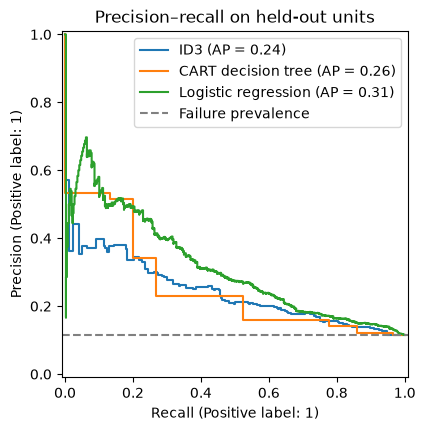

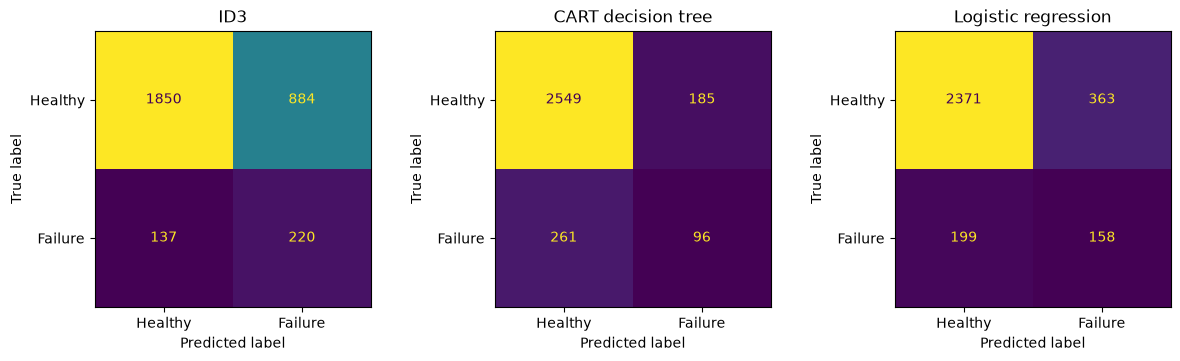

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, scores in test_scores.items():
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Failure prevalence")
ax.set_title("Precision-recall on held-out units")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, len(models), figsize=(12, 3.5), layout="constrained")
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], display_labels=["Healthy", "Failure"],
        colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.show()

### Learned CART rules

Read each split from the root. The left branch satisfies the displayed condition and the right branch takes the remaining observations. Numeric thresholds are in the preprocessed feature scale. Thresholds of 0.5 on one-hot columns separate a category from its complement. Node colors show the majority class during training. The evaluation uses the development-selected threshold from the table above.

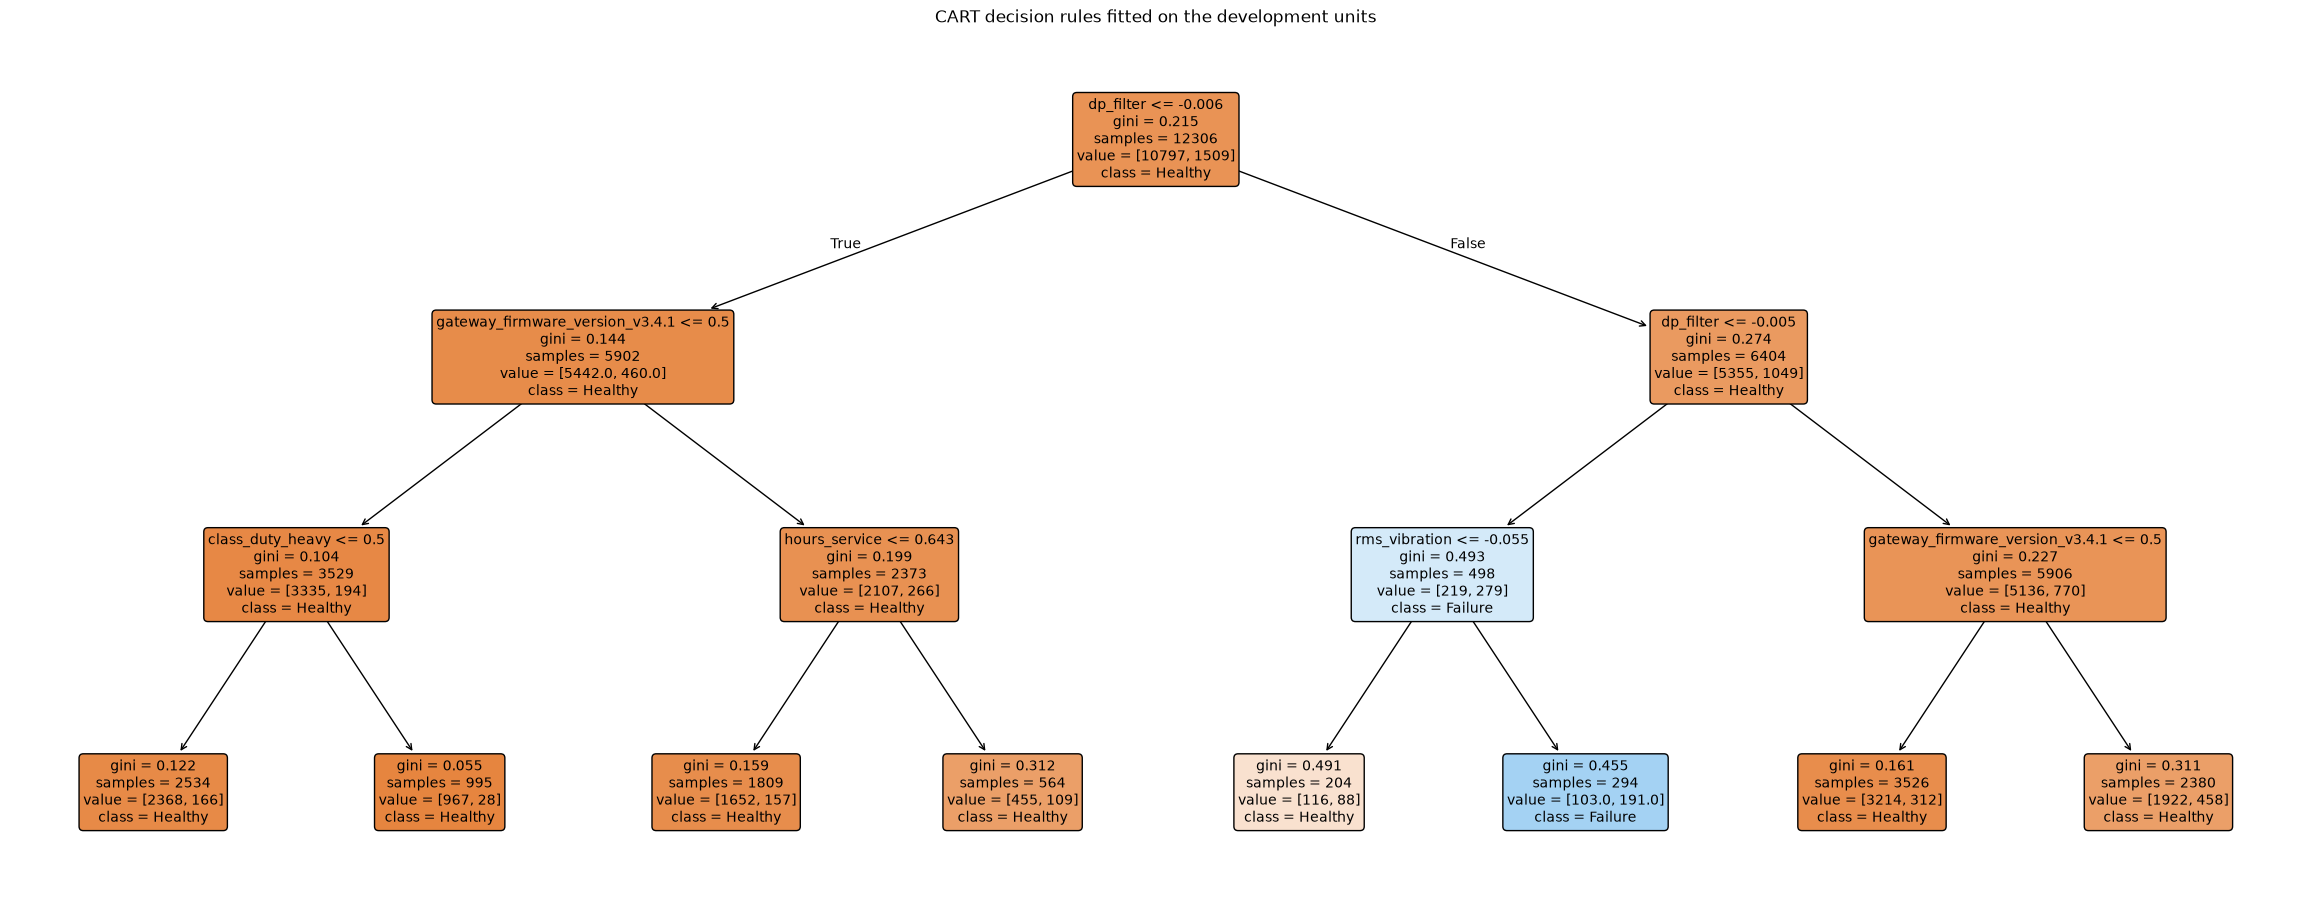

In [13]:
cart = fitted_models["CART decision tree"]
fig, ax = plt.subplots(figsize=(23, 9), layout="constrained")
plot_tree(
    cart.named_steps["classifier"],
    feature_names=cart[:-1].get_feature_names_out().tolist(),
    class_names=["Healthy", "Failure"], filled=True, rounded=True, fontsize=10, ax=ax,
)
ax.set_title("CART decision rules fitted on the development units")
plt.show()

### Results on unseen units

Logistic regression has the highest held-out AP (0.313), ROC AUC (0.731), and F1 (0.360). CART ranks second by AP (0.256), followed by ID3 (0.241). All three exceed the failure-prevalence baseline of 0.115.

At the selected thresholds, ID3 catches 220 of 357 failures (61.6% recall) and raises 884 false alarms. CART raises the fewest false alarms (185) and catches 96 failures. Logistic regression catches 158 failures with 363 false alarms. These results compare the models on new units for the observed cycle. They do not measure how far ahead a failure can be predicted.

CART uses `dp_filter` for the root split and uses it again on the right branch. That second split isolates a narrow range of preprocessed filter-pressure readings, which the next rule divides by `rms_vibration`. ID3's quantile bins give it coarser numeric boundaries, and it can use each attribute only once on a path.